In [76]:
#Import the necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [77]:
data=pd.read_csv("Tesla - Deaths.csv")

#Step 1:Prelimnary Data inspection and cleaning

In [78]:
data.head()

,Case #,Year,Date,Country,State,Description,Deaths,Tesla driver,Tesla occupant,Other vehicle,...,Verified Tesla Autopilot Deaths,Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO,Unnamed: 16,Unnamed: 17,Source,Note,Deceased 1,Deceased 2,Deceased 3,Deceased 4
0,294.0,2022.0,1/17/2023,USA,CA,Tesla crashes into back of semi,1.0,1,-,-,...,-,-,https://web.archive.org/web/20221222203930/ht...,https://web.archive.org/web/20221222203930/ht...,https://web.archive.org/web/20230118162813/ht...,NaN,NaN,NaN,NaN,NaN
1,293.0,2022.0,1/7/2023,Canada,-,Tesla crashes,1.0,1,-,-,...,-,-,https://web.archive.org/web/20221222203930/ht...,https://web.archive.org/web/20221222203930/ht...,https://web.archive.org/web/20230109041434/ht...,NaN,Taren Singh Lal,NaN,NaN,NaN
2,292.0,2022.0,1/7/2023,USA,WA,"Tesla hits pole, catches on fire",1.0,-,1,-,...,-,-,https://web.archive.org/web/20221222203930/ht...,https://web.archive.org/web/20221222203930/ht...,https://web.archive.org/web/20230107232745/ht...,NaN,NaN,NaN,NaN,NaN
3,291.0,2022.0,12/22/2022,USA,GA,Tesla crashes and burns,1.0,1,-,-,...,-,-,https://web.archive.org/web/20221222203930/ht...,https://web.archive.org/web/20221222203930/ht...,https://web.archive.org/web/20221222203930/ht...,NaN,NaN,NaN,NaN,NaN
4,290.0,2022.0,12/19/2022,Canada,-,Tesla crashes into storefront,1.0,-,-,-,...,-,-,https://web.archive.org/web/20221223203725/ht...,https://web.archive.org/web/20221223203725/ht...,https://web.archive.org/web/20221223203725/ht...,NaN,NaN,NaN,NaN,NaN


#1(a) Check for data types, missing values and duplicates

In [79]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307 entries, 0 to 306
Data columns (total 24 columns):
 #   Column                                                                Non-Null Count  Dtype  
---  ------                                                                --------------  -----  
 0   Case #                                                                294 non-null    float64
 1   Year                                                                  294 non-null    float64
 2   Date                                                                  294 non-null    object 
 3    Country                                                              294 non-null    object 
 4    State                                                                294 non-null    object 
 5    Description                                                          295 non-null    object 
 6    Deaths                                                               299 non-null    float64
 7  

In [80]:
#Drop any duplicate values
data.drop_duplicates(inplace=True, ignore_index=True)

In [81]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 24 columns):
 #   Column                                                                Non-Null Count  Dtype  
---  ------                                                                --------------  -----  
 0   Case #                                                                294 non-null    float64
 1   Year                                                                  294 non-null    float64
 2   Date                                                                  294 non-null    object 
 3    Country                                                              294 non-null    object 
 4    State                                                                294 non-null    object 
 5    Description                                                          295 non-null    object 
 6    Deaths                                                               299 non-null    float64
 7  

In [82]:
print(data.columns)


Index(['Case #', 'Year', 'Date', ' Country ', ' State ', ' Description ',
       ' Deaths ', ' Tesla driver ', ' Tesla occupant ', ' Other vehicle ',
       ' Cyclists/ Peds ', ' TSLA+cycl / peds ', ' Model ',
       ' Autopilot claimed ', ' Verified Tesla Autopilot Deaths ',
       ' Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO ',
       'Unnamed: 16', 'Unnamed: 17', ' Source ', ' Note ', ' Deceased 1 ',
       ' Deceased 2 ', ' Deceased 3 ', ' Deceased 4 '],
      dtype='object')


In [83]:
#Removing the unecessary space before and after the name of column
data.columns = data.columns.str.strip()

Change the data type of columns as per given information

Check the unique value for each column and removing unecessary values

In [84]:
data['Year'].unique()

array([2022., 2020., 2021.,  202., 2019., 2018., 2017., 2016., 2015.,
       2014., 2013.,   nan])

In [85]:
data['Date'].unique()

array(['1/17/2023', '1/7/2023', '12/22/2022', '12/19/2022', '12/18/2022',
       '12/17/2022', '12/11/2022', '12/6/2022', '11/28/2022',
       '11/27/2022', '11/26/2022', '11/18/2022', '11/12/2022',
       '11/11/2022', '11/5/2022', '11/4/2022', '10/19/2022', '10/18/2022',
       '10/12/2022', '10/9/2022', '10/1/2022', '9/18/2022', '9/16/2022',
       '9/13/2022', '9/12/2022', '9/7/2022', '8/30/2022', '8/26/2022',
       '8/24/2022', '8/23/2022', '8/21/2022', '8/20/2022', '8/16/2022',
       '8/14/2022', '8/2/2022', '7/27/2022', '7/24/2022', '7/16/2022',
       '7/12/2022', '7/8/2022', '7/7/2022', '7/6/2022', '7/5/2022',
       '6/26/2022', '6/20/2022', '6/19/2022', '6/17/2022', '6/14/2022',
       '6/13/2022', '6/7/2022', '6/3/2022', '5/28/2022', '5/25/2022',
       '5/23/2022', '5/21/2022', '5/19/2022', '5/18/2022', '5/17/2022',
       '5/12/2022', '5/11/2022', '5/7/2022', '5/1/2022', '4/29/2022',
       '4/14/2022', '4/10/2022', '4/8/2022', '3/26/2022', '3/21/2022',
       '3/20/202

In [86]:
data['Country'].unique()

array([' USA ', ' Canada ', ' China ', ' Mexico ', ' UK ', ' Germany ',
       ' Finland ', ' Australia ', ' Netherlands ', ' Switzerland ',
       ' France ', ' Denmark ', ' Belgium ', ' Portugal ',
       ' South Korea ', ' Norway ', ' Taiwan ', ' Slovenia ', ' Austria ',
       ' Ukraine ', ' Spain ', ' Holland ', ' Japan ', nan], dtype=object)

In [87]:
data['State'].unique()

array(['CA', '-', 'WA', 'GA', 'MO', 'AR', 'IL', 'FL', 'SC', 'MD', 'NY',
       'MA', 'ME', 'UT', 'PA', 'HA', 'AL', ' MI ', ' CA ', ' NV ', ' NY ',
       ' OR ', ' AZ ', ' NJ ', ' CO ', ' UT ', ' PA ', ' NC ', ' FL ',
       ' ID ', ' MO ', ' OH ', ' GA ', ' IA ', ' WA ', ' VA ', ' TX ',
       ' IL ', ' IN ', ' DE ', ' NH ', ' TN ', ' HI ', nan], dtype=object)

In [88]:
data['Deaths'].unique()

array([1.000e+00, 2.000e+00, 4.000e+00, 3.000e+00, 9.200e+01, 2.610e+02,
       3.530e+02,       nan, 2.013e+03])

In [89]:
print(data['Other vehicle'].unique())

[' - ' '  1 ' '  2 ' nan '  3 ' '  4 ' '  29 ' '  101 ' '  130 ' '  16 '
 '2016']


In [90]:
print(data['Cyclists/ Peds'].unique())

[' - ' '  1 ' '  2 ' nan '  20 ' '  26 ' '  46 ' '  11 ' '2017']


In [91]:
print(data['TSLA+cycl / peds'].unique())

['  1 ' ' - ' '  2 ' '  3 ' '  4 ' nan '  61 ' '  149 ' '  210 ' '  21 '
 '2018']


In [92]:
print(data['Model'].unique())

[' - ' ' Y ' '  1 ' '  2 ' '  3 ' ' S ' ' X ' nan '  50 ' '2019']


In [93]:
#Removing the unecessary values in the column such as '-' and filling the missing values with statistical approach
import numpy as np
data['State'] = data['State'].replace('-', np.nan)
data['State'] = data['State'].replace(' - ', np.nan)
data['State'].fillna(data['State'].mode()[0],inplace=True)

data['Other vehicle'] = data['Other vehicle'].replace('-', np.nan)
data['Other vehicle'] = data['Other vehicle'].replace(' - ', np.nan)
data['Other vehicle'] = pd.to_numeric(data['Other vehicle'], errors='coerce')


data['Cyclists/ Peds'] = data['Other vehicle'].replace('-', np.nan)
data['Cyclists/ Peds'] = data['Other vehicle'].replace(' - ', np.nan)
data['Cyclists/ Peds'] = pd.to_numeric(data['Other vehicle'], errors='coerce')

data['TSLA+cycl / peds'] = data['Other vehicle'].replace('-', np.nan)
data['TSLA+cycl / peds'] = data['Other vehicle'].replace(' - ', np.nan)
data['TSLA+cycl / peds'] = pd.to_numeric(data['Other vehicle'], errors='coerce')


data['Verified Tesla Autopilot Deaths'] = data['Other vehicle'].replace('-', np.nan)
data['Verified Tesla Autopilot Deaths'] = data['Other vehicle'].replace(' - ', np.nan)
data['Verified Tesla Autopilot Deaths'] = pd.to_numeric(data['Other vehicle'], errors='coerce')

data['Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO'] = data['Other vehicle'].replace('-', np.nan)
data['Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO'] = data['Other vehicle'].replace(' - ', np.nan)
data['Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO'] = pd.to_numeric(data['Other vehicle'], errors='coerce')



/tmp/ipython-input-486/3024381498.py:5: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['State'].fillna(data['State'].mode()[0],inplace=True)


In [94]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 24 columns):
 #   Column                                                              Non-Null Count  Dtype  
---  ------                                                              --------------  -----  
 0   Case #                                                              294 non-null    float64
 1   Year                                                                294 non-null    float64
 2   Date                                                                294 non-null    object 
 3   Country                                                             294 non-null    object 
 4   State                                                               303 non-null    object 
 5   Description                                                         295 non-null    object 
 6   Deaths                                                              299 non-null    float64
 7   Tesla driver     

In [95]:
data.isnull().sum()

,0
Case #,9
Year,9
Date,9
Country,9
State,0
Description,8
Deaths,4
Tesla driver,9
Tesla occupant,13
Other vehicle,188


In [96]:
#Filling the missing values in the required feature columns with satistcal approach wherever applicable
data['Year'].fillna(data['Year'].mean(),inplace=True)
data['Date'].fillna(data['Date'].mode()[0],inplace=True)
data['Country'].fillna(data['Country'].mode()[0],inplace=True)
data['Description'].fillna(data['Description'].mode()[0],inplace=True)
data['Autopilot claimed'].fillna(data['Autopilot claimed'].mode()[0],inplace=True)
data['Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO'].fillna(data['Verified Tesla Autopilot Deaths + All Deaths Reported to NHTSA SGO'].mean(),inplace=True)

/tmp/ipython-input-486/3602048443.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['Year'].fillna(data['Year'].mean(),inplace=True)
/tmp/ipython-input-486/3602048443.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=T

In [97]:
data.isnull().sum()

,0
Case #,9
Year,0
Date,0
Country,0
State,0
Description,0
Deaths,4
Tesla driver,9
Tesla occupant,13
Other vehicle,188


#Step1(b): Removing any Unwated columns not required for analysis

In [98]:
#Splitting the data into features and column for further analysis
features=data.iloc[:,[0,1,2,3,4,5,6,7,8,9,10,11,12,14,15]]
label=data.iloc[:,13]

#Step2: Exploratary Data analysis

2(a). In-depth exploratory analysis on no. of events by date,per year, per day for each state and country

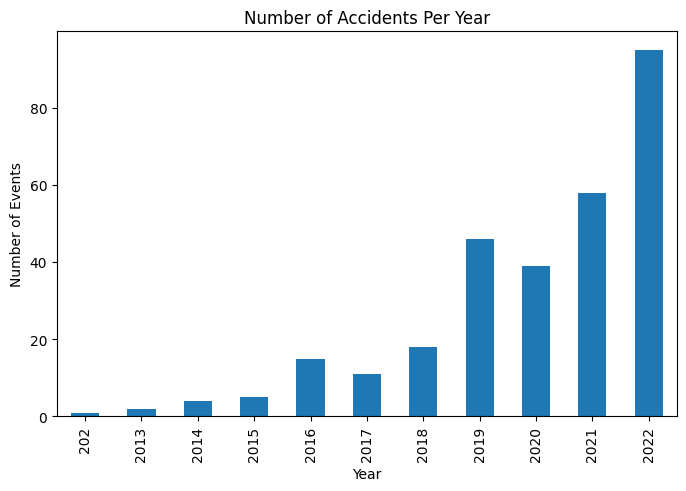

In [99]:
import seaborn as sns
data['Year']=data['Year'].astype(int)
#Events by year
events_per_year = data.groupby('Year')['Case #'].count()

plt.figure(figsize=(8,5))
events_per_year.plot(kind='bar')
plt.title("Number of Accidents Per Year")
plt.ylabel("Number of Events")
plt.show()




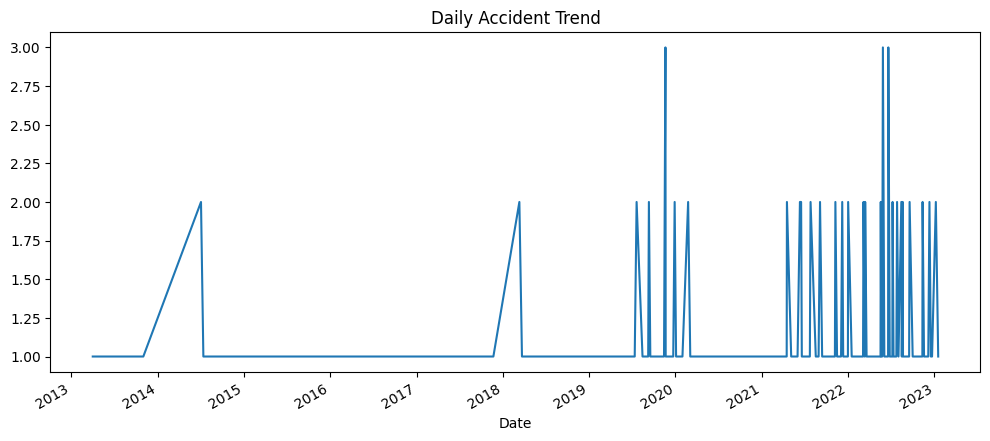

In [100]:
#Events per day
data['Date'] = pd.to_datetime(data['Date'])
events_per_day = data.groupby('Date')['Case #'].count()

plt.figure(figsize=(12,5))
events_per_day.plot()
plt.title("Daily Accident Trend")
plt.show()

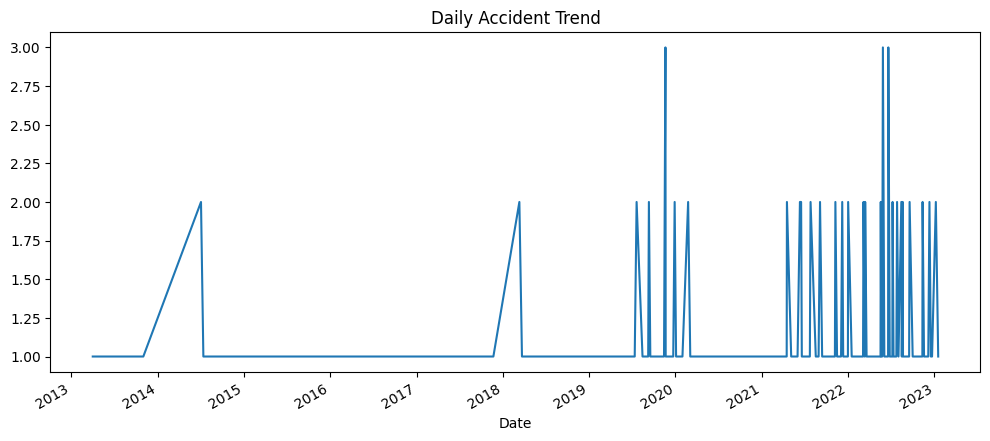

In [101]:
#Events by week
data['Weekday'] = data['Date'].dt.day_name()
data['Weekday'].value_counts()
events_per_week = data.groupby('Weekday')['Case #'].count()

plt.figure(figsize=(12,5))
events_per_day.plot()
plt.title("Daily Accident Trend")
plt.show()


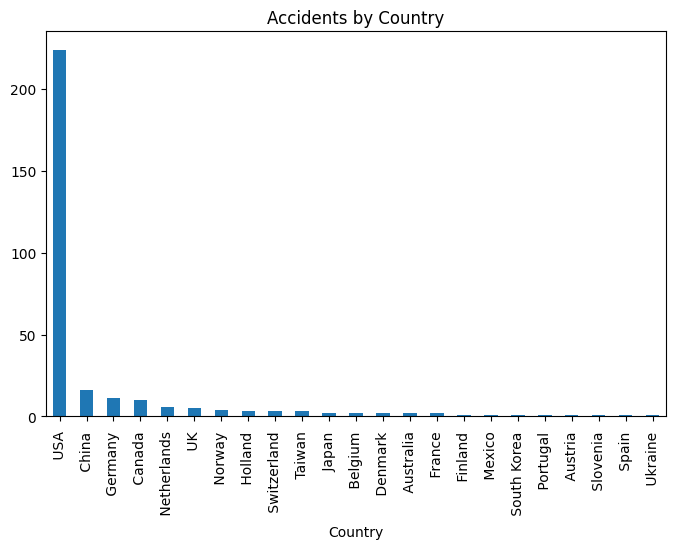

In [102]:
#Events by country
country_counts = data['Country'].value_counts()

plt.figure(figsize=(8,5))
country_counts.plot(kind='bar')
plt.title("Accidents by Country")
plt.show()

In [103]:
data['State'].unique()

array(['CA', ' CA ', 'WA', 'GA', 'MO', 'AR', 'IL', 'FL', 'SC', 'MD', 'NY',
       'MA', 'ME', 'UT', 'PA', 'HA', 'AL', ' MI ', ' NV ', ' NY ', ' OR ',
       ' AZ ', ' NJ ', ' CO ', ' UT ', ' PA ', ' NC ', ' FL ', ' ID ',
       ' MO ', ' OH ', ' GA ', ' IA ', ' WA ', ' VA ', ' TX ', ' IL ',
       ' IN ', ' DE ', ' NH ', ' TN ', ' HI '], dtype=object)

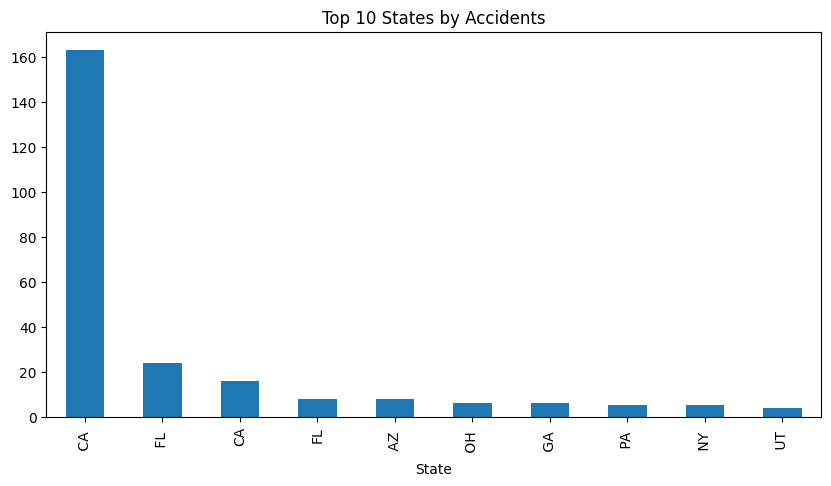

In [104]:
state_counts = data['State'].value_counts().head(10)

plt.figure(figsize=(10,5))
state_counts.plot(kind='bar')
plt.title("Top 10 States by Accidents")
plt.show()

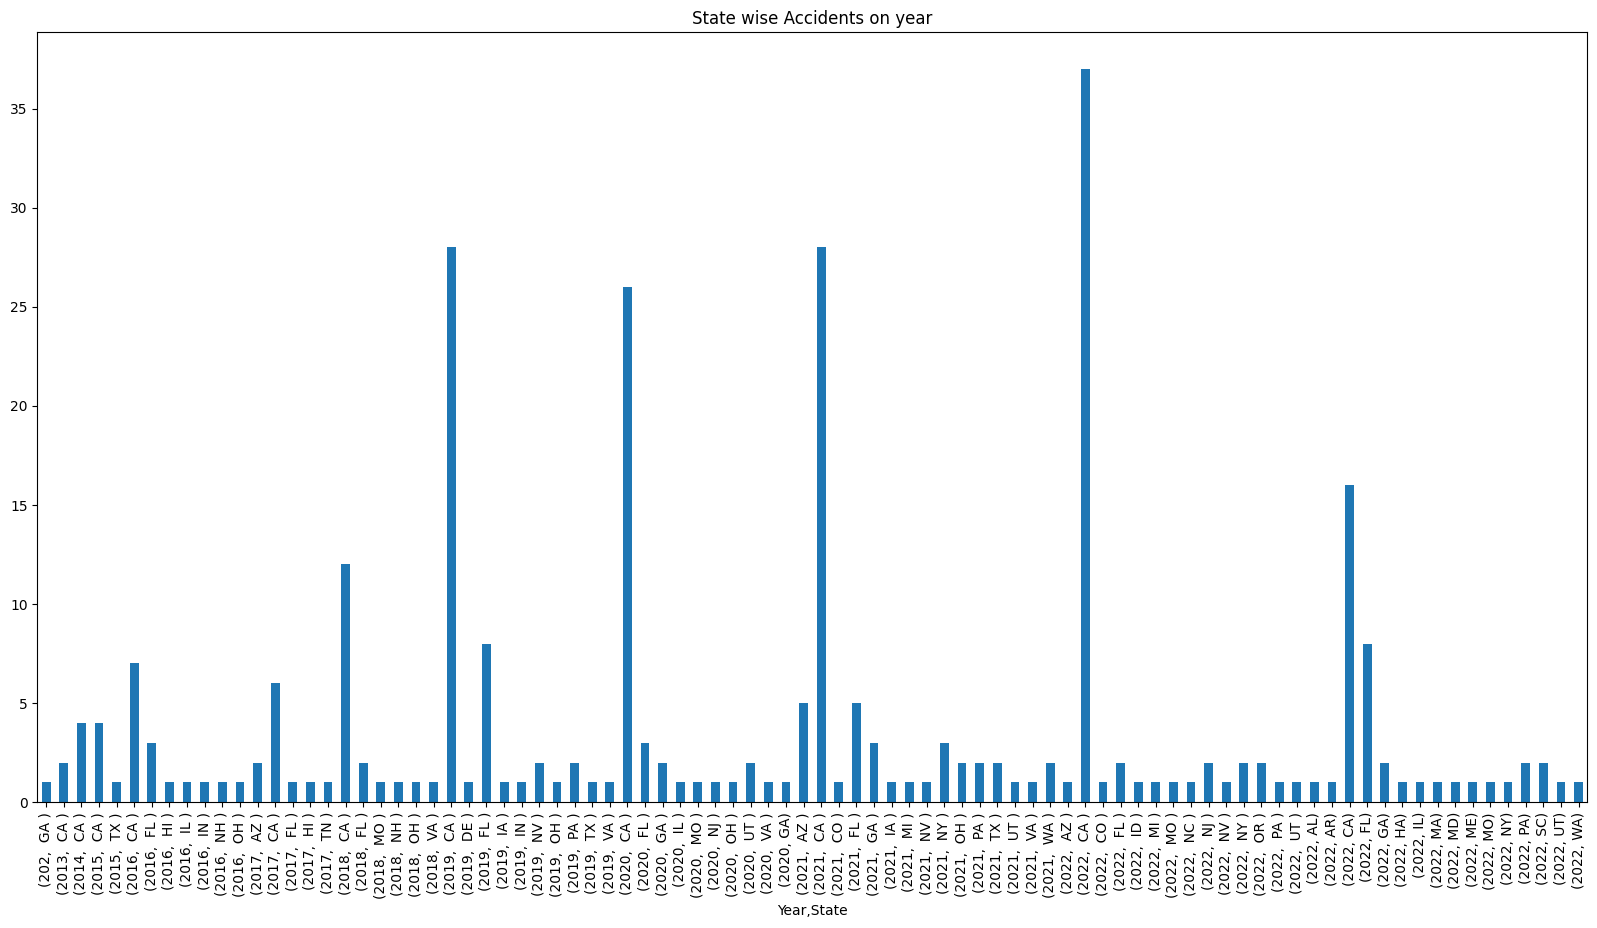

In [105]:
state_year = data.groupby(['Year','State'])['Case #'].count()
plt.figure(figsize=(20,10))
state_year.plot(kind='bar')
plt.title("State wise Accidents on year")
plt.show()

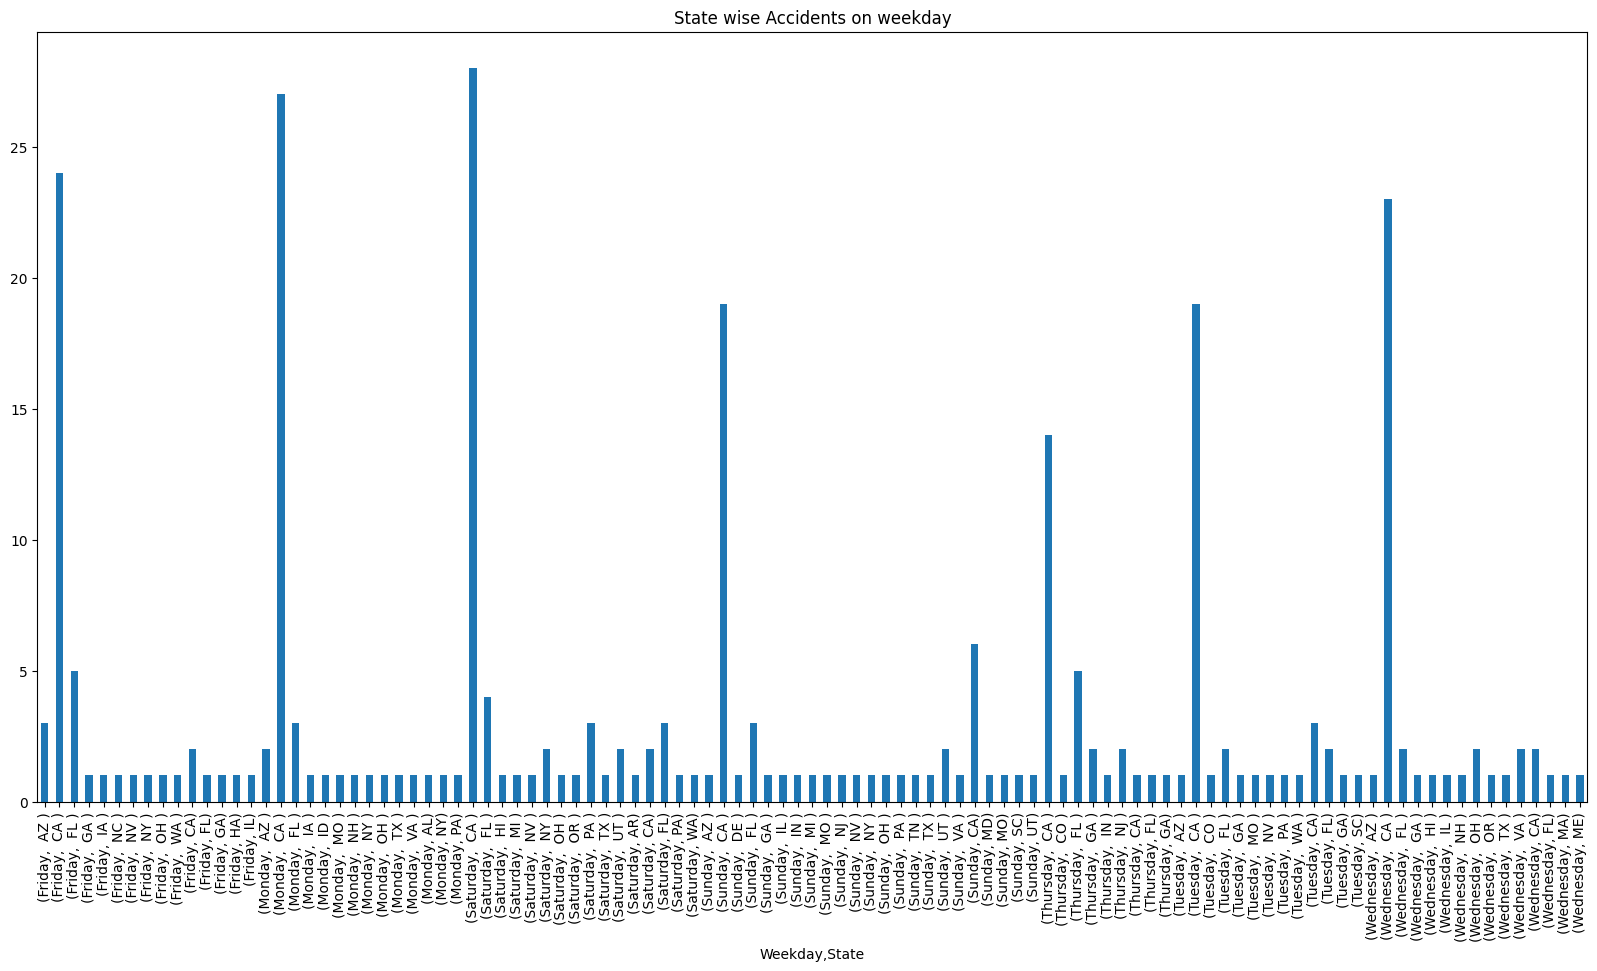

In [106]:
state_weekday = data.groupby(['Weekday','State'])['Case #'].count()
plt.figure(figsize=(20,10))
state_weekday.plot(kind='bar')
plt.title("State wise Accidents on weekday")
plt.show()

In [107]:
state_date = data.groupby(['Date','State'])['Case #'].count()
plt.figure(figsize=(150,100))
state_date.plot(kind='bar')
plt.title("State wise Accidents on weekday")
plt.show()

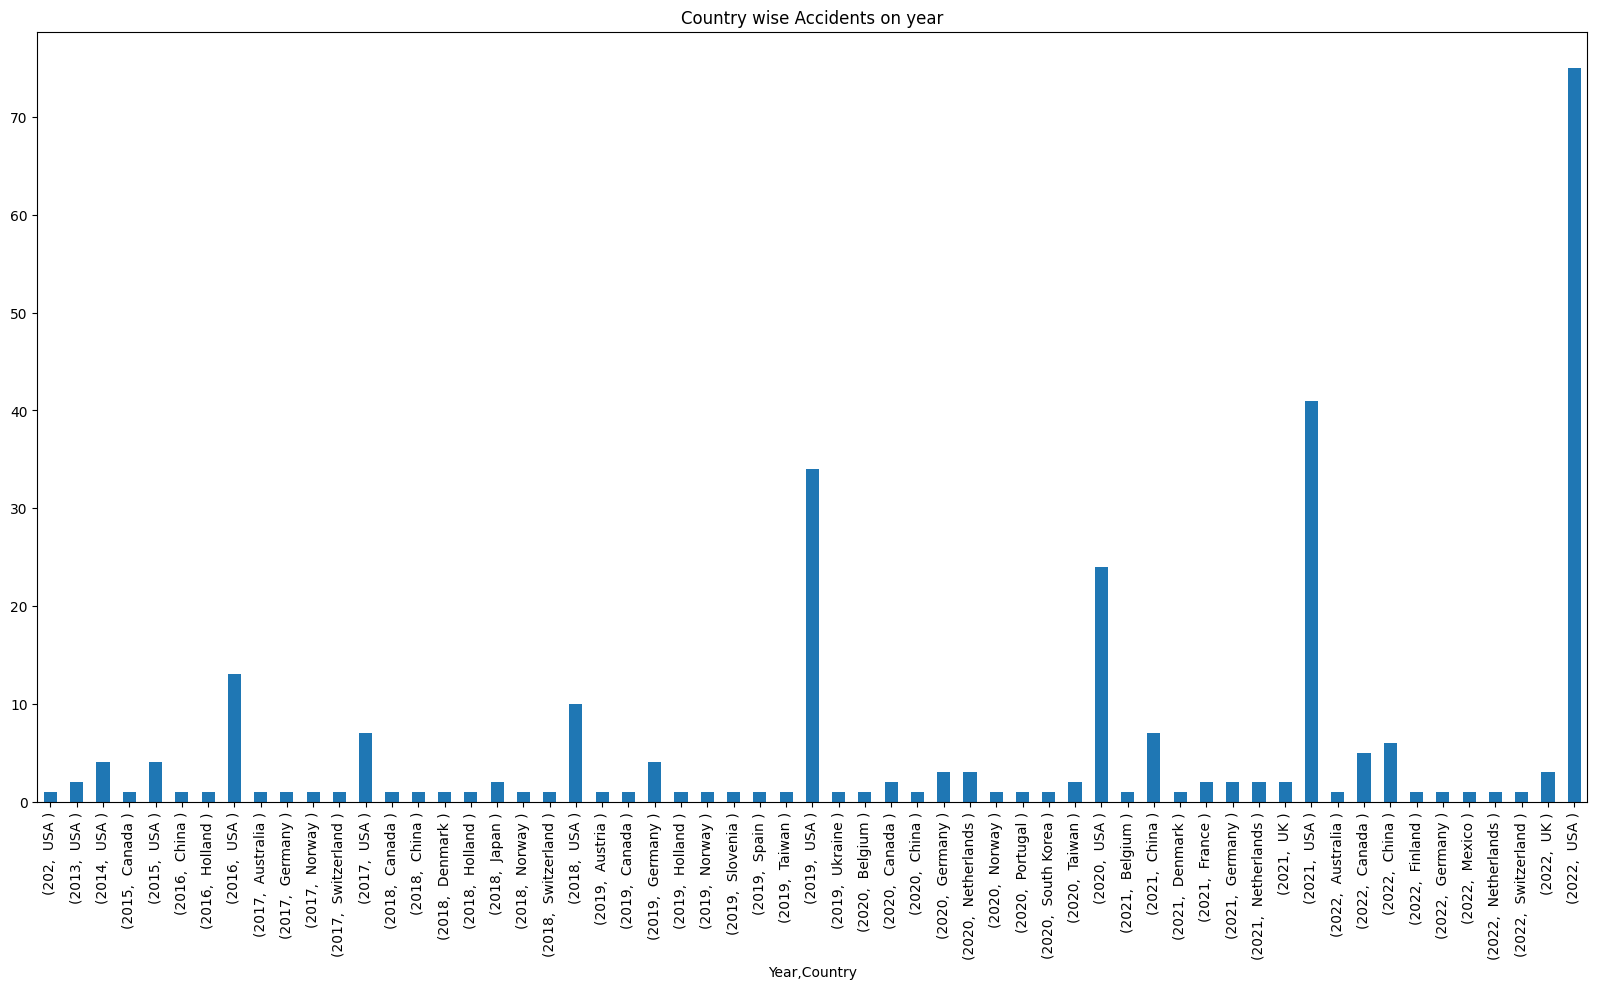

In [108]:
#Year wise country accidents
country_year = data.groupby(['Year','Country'])['Case #'].count()
plt.figure(figsize=(20,10))
country_year.plot(kind='bar')
plt.title("Country wise Accidents on year")
plt.show()

#Step2(b): Death Analysis



*  The number of victims (deaths) in each accident



In [109]:
#Remove unrealistic values
data.loc[data['Deaths'] > 6, 'Deaths'] = np.nan

In [110]:
#Checking  and removing the nan values in the data
before = data.shape[0]
data = data.dropna(subset=['Deaths'])
after = data.shape[0]

print("Rows removed:", before - after)

Rows removed: 8


In [111]:
#No. deaths in each accident
data['Deaths'].value_counts()

,count
Deaths,
1.0,247
2.0,38
3.0,7
4.0,3


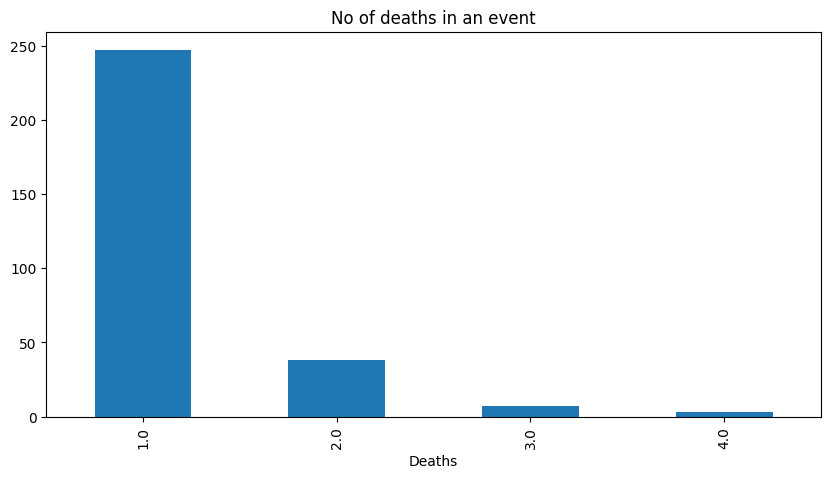

In [112]:
death_counts = data['Deaths'].value_counts()

plt.figure(figsize=(10,5))
death_counts.plot(kind='bar')
plt.title("No of deaths in an event")
plt.show()

The analysis of the Deaths variable indicates that the majority of Tesla-related fatal accidents involved a single fatality. Specifically, most cases recorded one death, while a smaller number of accidents involved two or more fatalities. Multi-fatality accidents (three or more deaths) were relatively rare.

During exploratory analysis, a few anomalous values were observed in the Deaths column that exceeded realistic limits for a single accident. These values were treated as data inconsistencies and handled appropriately to ensure analytical accuracy. After cleaning, the distribution reflects realistic fatality counts per incident.

The findings suggest that while fatal accidents do occur, they are predominantly single-fatality events rather than large-scale incidents. This pattern is consistent with typical road accident statistics, where most fatal crashes involve one victim.

Overall, the death distribution highlights the importance of analyzing accident severity and understanding whether specific conditions (such as autopilot usage, model type, or collision with other vehicles) contribute to higher fatality counts.



*  No. of times tesla drivers died



In [113]:
data['Tesla driver'].unique()

array(['  1 ', ' - ', nan, '  6 '], dtype=object)

In [114]:
#Removing the unecessary values in the column such as '-' and converting the column value into numerical values
import numpy as np

data['Tesla driver'] = data['Tesla driver'].replace((' - ','  6 '), np.nan)
data['Tesla driver'] = pd.to_numeric(data['Tesla driver'], errors='coerce')

In [115]:
data['Tesla driver'].dtype

dtype('float64')

In [116]:
#Filling the missing value with relevant value
data['Tesla driver'] = data['Tesla driver'].fillna(0)

In [117]:
data['Tesla driver'].value_counts()

,count
Tesla driver,
0.0,178
1.0,117


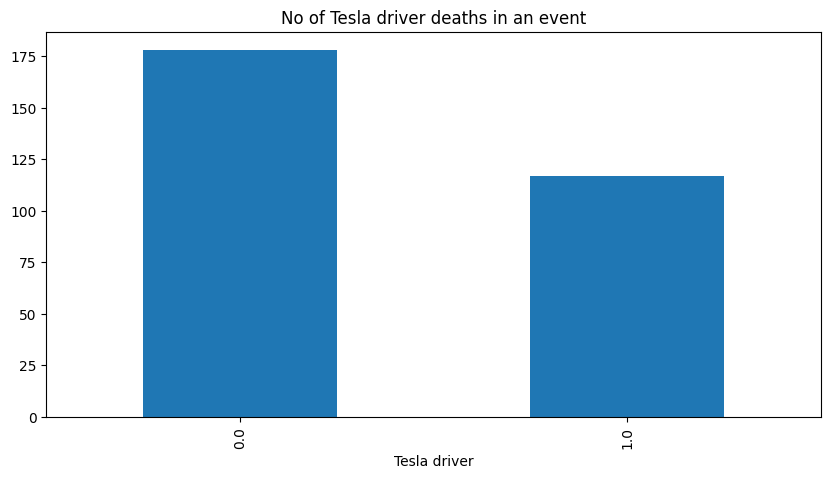

In [118]:
Tesla_driver_death_counts = data['Tesla driver'].value_counts()

plt.figure(figsize=(10,5))
Tesla_driver_death_counts.plot(kind='bar')
plt.title("No of Tesla driver deaths in an event")
plt.show()

Out of all recorded fatal incidents, 117 cases involved the death of a Tesla driver.



*   **Proportion of events in which one or more occupant died**



In [119]:
data['Tesla occupant'].unique()

array([' - ', '  1 ', '  3 ', nan, '  2 ', '  5 '], dtype=object)

In [120]:
#Replacing the unecessary values in the column such as '-' with nan and converting the column value into numerical values
data['Tesla occupant'] = data['Tesla occupant'].replace('-', np.nan)
data['Tesla occupant'] = pd.to_numeric(data['Tesla occupant'], errors='coerce')

In [121]:
#Filling the missing value with relevant value

data['Tesla occupant'] = data['Tesla occupant'].fillna(0)

In [122]:
#Calculating the proportion of events in which tesla occupant died
occupant_events = data[data['Tesla occupant'] > 0].shape[0]
total_events = data.shape[0]

proportion = occupant_events / total_events
print(proportion)

0.14915254237288136


It means out of all occupants there were 15 percent of occupant were of Tesla



*   **The distribution of events in which the vehicle hit a cyclist or a pedestrian**  



In [123]:
data['Cyclists/ Peds'].unique()

array([nan,  1.,  2.,  3.,  4., 16.])

In [124]:
data['Cyclists/ Peds'].value_counts()

,count
Cyclists/ Peds,
1.0,95
2.0,11
3.0,3
4.0,1
16.0,1


In [125]:
#Filling the missing value with relevant value
data['Cyclists/ Peds'] = data['Other vehicle'].replace('16', np.nan)
data['Cyclists/ Peds'] = data['Cyclists/ Peds'].fillna(0)

In [126]:
data['Cyclists/ Peds'].sum()

np.float64(146.0)

Out of all recorded fatal incidents, 146 cases involved the death of cyclists and pedestarian deaths



*   Events that involve death of Tesla driver and Cyclist/pedestarian together





In [127]:
data['TSLA+cycl / peds'].unique()

array([nan,  1.,  2.,  3.,  4., 16.])

In [128]:
#Replacing the irrelevant row value with nana
data['TSLA+cycl / peds'] = data['TSLA+cycl / peds'].replace('16', np.nan)

In [129]:
#Filling the missing value with relevant value

data['TSLA+cycl / peds'] = data['TSLA+cycl / peds'].fillna(0)

In [130]:
data['TSLA+cycl / peds'].value_counts()

,count
TSLA+cycl / peds,
0.0,184
1.0,95
2.0,11
3.0,3
4.0,1
16.0,1


In [131]:
data['TSLA+cycl / peds'].sum()

np.float64(146.0)

It means 55 events involve death of Tesla driver and Cyclist/pedestaian together



*   Frequency of Tesla colliding with other vehicle



In [132]:
data['Other vehicle'].unique()

array([nan,  1.,  2.,  3.,  4., 16.])

In [133]:
data['Other vehicle'].value_counts()

,count
Other vehicle,
1.0,95
2.0,11
3.0,3
4.0,1
16.0,1


In [134]:
#Remove unrealistic values since values such as 101,130,16,2016 is non-realistic
data.loc[data['Other vehicle'] > 6, 'Other vehicle'] = np.nan

In [135]:
#Filling the missing value with relevant value
data['Other vehicle']=data['Other vehicle'].fillna(0)

In [136]:
data['Other vehicle'].value_counts()

,count
Other vehicle,
0.0,185
1.0,95
2.0,11
3.0,3
4.0,1


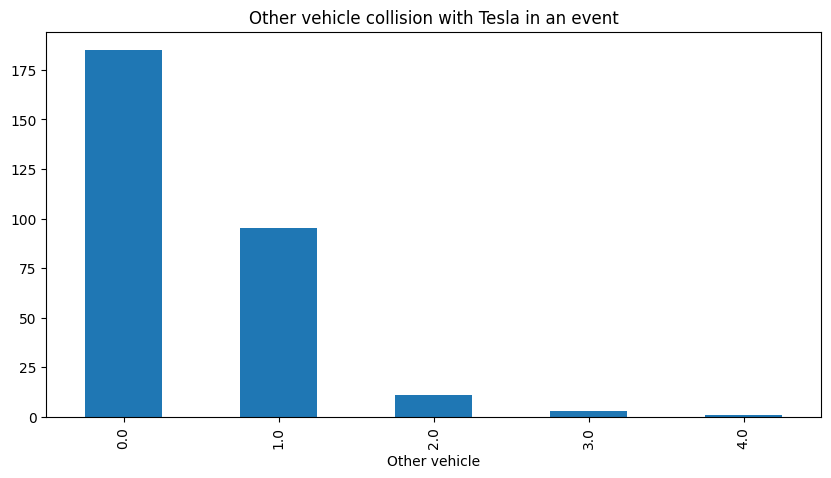

In [137]:
#Analysing the total deaths from vehicle collision through graph
death_counts = data['Other vehicle'].value_counts().sort_index()

plt.figure(figsize=(10,5))
death_counts.plot(kind='bar')
plt.title("Other vehicle collision with Tesla in an event")
plt.show()

In [138]:
print(sorted(data['Other vehicle'].unique()))

[np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]


The analysis of the “Other vehicle” variable indicates that the majority of incidents involved either no additional motor vehicle or only one other vehicle. A smaller proportion of cases involved two or more vehicles, while multi-vehicle collisions (three or more vehicles) were relatively rare. During exploratory analysis, a few anomalous values exceeding realistic collision limits were identified and treated as data inconsistencies. After appropriate cleaning, the distribution reflects plausible and realistic collision patterns per incident.

This suggests that most fatal Tesla-related incidents are not large multi-vehicle pileups but rather involve limited vehicle interaction.

#Step2(c): Event distribution accross models

In [139]:
data['Model'].unique()

array([' - ', ' Y ', '  1 ', '  2 ', '  3 ', ' S ', ' X ', '  50 '],
      dtype=object)

In [140]:
#Replacing the unecessary values in the column such as '-' with nan
data['Model'] = data['Model'].replace(' - ', np.nan)

In [141]:
data = data[~data['Model'].isin(['  50 ', '2019'])]

In [142]:
# Removing the nan values in column due to limited exposure name of model
data = data.dropna(subset=['Model'])

In [143]:
print(data['Model'].unique())

[' Y ' '  1 ' '  2 ' '  3 ' ' S ' ' X ']


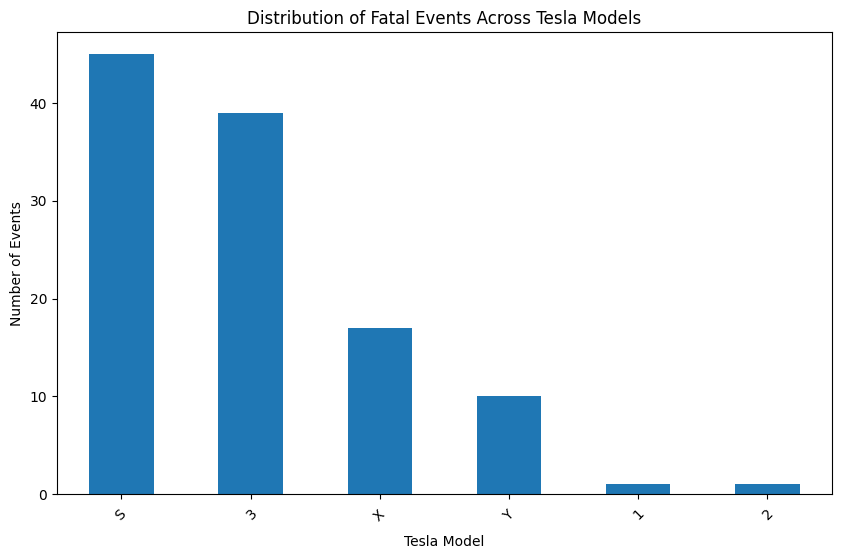

In [144]:
#Analysing the model wise distribution of death through graph
model_counts = data['Model'].value_counts()

plt.figure(figsize=(10,6))
model_counts.plot(kind='bar')
plt.title("Distribution of Fatal Events Across Tesla Models")
plt.xlabel("Tesla Model")
plt.ylabel("Number of Events")
plt.xticks(rotation=45)
plt.show()

During model-wise analysis, certain invalid entries such as '-' and numeric values (e.g., 50, 2019) were identified in the Model column. These were treated as data inconsistencies and removed to ensure accurate representation of Tesla model distribution.

The analysis of fatal incidents across Tesla models indicates that the majority of recorded events involve Model S and Model 3. Model S shows the highest number of fatal incidents, followed closely by Model 3. Model X and Model Y account for comparatively fewer cases, while older or less common models appear only minimally in the dataset.

This distribution likely reflects differences in production volume, market presence, and years of operation rather than inherent safety performance. Therefore, while Model S and Model 3 exhibit higher incident counts, these figures should be interpreted in the context of overall exposure and usage rates. Further analysis incorporating fleet size and miles driven would be necessary to draw definitive conclusions regarding relative safety across models

#Step2(d): Verified autopilot death

In [145]:
data['Verified Tesla Autopilot Deaths'].unique()

array([ 2., nan,  1.,  3.])

In [146]:
data['Verified Tesla Autopilot Deaths'].value_counts()

,count
Verified Tesla Autopilot Deaths,
1.0,42
2.0,5
3.0,1


In [147]:
#Repalcing the missing values with zero
data['Verified Tesla Autopilot Deaths']=data['Verified Tesla Autopilot Deaths'].fillna(0)

In [148]:
data['Verified Tesla Autopilot Deaths'].value_counts()

,count
Verified Tesla Autopilot Deaths,
0.0,65
1.0,42
2.0,5
3.0,1


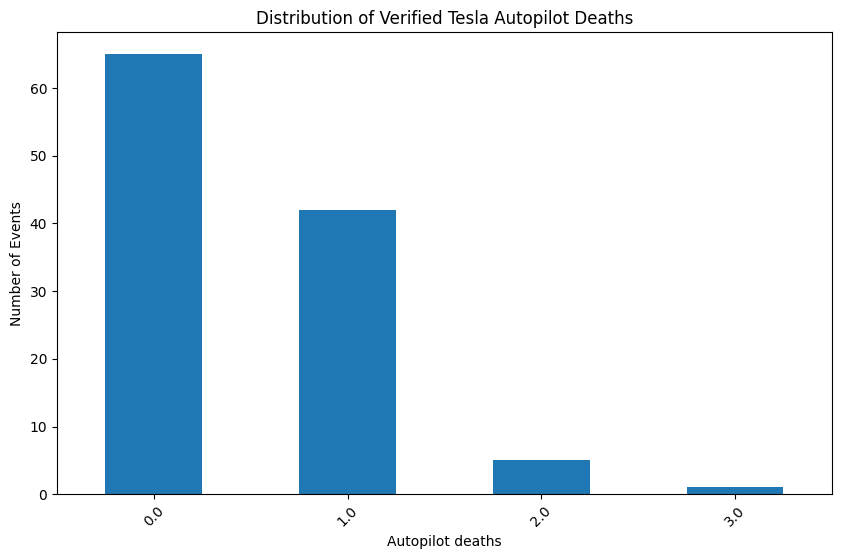

In [149]:
Autopilot_death_counts = data['Verified Tesla Autopilot Deaths'].value_counts()

plt.figure(figsize=(10,6))
Autopilot_death_counts.plot(kind='bar')
plt.title("Distribution of Verified Tesla Autopilot Deaths")
plt.xlabel("Autopilot deaths")
plt.ylabel("Number of Events")
plt.xticks(rotation=45)
plt.show()

The distribution of verified Tesla Autopilot deaths indicates that the majority of fatal incidents in the dataset were not officially confirmed to involve Autopilot functionality. Most events recorded zero verified Autopilot-related deaths, while a smaller proportion involved one confirmed Autopilot fatality. Incidents involving two or more verified Autopilot deaths were relatively rare.

This suggests that although Autopilot-related accidents receive significant public and media attention, they constitute only a subset of total fatal Tesla-related incidents in the dataset. Therefore, conclusions regarding Autopilot safety should be drawn carefully and in the context of overall driving exposure and verification status.

Further investigation incorporating driving exposure metrics and verification criteria would provide a more comprehensive assessment of Autopilot-related risk.

#NOTE:
In the death-related variables (Tesla driver, Tesla occupant, cyclists/pedestrians, combined fatalities, and verified Autopilot deaths), missing values were interpreted as the absence of recorded fatalities for that category. Since these variables represent count-based event outcomes, missing entries were replaced with zero to indicate no deaths occurred in that specific category. This assumption ensures analytical consistency while avoiding inflation of fatality counts.